In [ ]:
import numpy as np
import pandas as pd

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Placeholder for an image path. You can replace this with your own image file.
# For example, you might upload an image to Colab's file system or use a URL.
# If you don't have an image, you can create a dummy one for demonstration.
image_path = 'path/to/your/image.jpg' # <<< REPLACE WITH YOUR IMAGE PATH

# --- Create a dummy image if no path is provided for demonstration purposes ---
# If you don't have an image, uncomment the following lines to create a dummy 640x640 RGB image
# from io import BytesIO
# import base64
# if image_path == 'path/to/your/image.jpg':
#     print("No image path provided, creating a dummy image for demonstration.")
#     dummy_image_data = np.random.randint(0, 256, (640, 640, 3), dtype=np.uint8)
#     dummy_img = Image.fromarray(dummy_image_data, 'RGB')
#     # Save to a BytesIO object to simulate loading
#     img_byte_arr = BytesIO()
#     dummy_img.save(img_byte_arr, format='PNG')
#     img_byte_arr.seek(0)
#     image = Image.open(img_byte_arr)
# else:
#     image = Image.open(image_path)

# For simplicity, let's assume 'image_path' points to a valid image or we'll use a dummy for now
try:
    image = Image.open(image_path)
except FileNotFoundError:
    print(f"Image not found at {image_path}. Creating a dummy image for demonstration.")
    dummy_image_data = np.random.randint(0, 256, (640, 640, 3), dtype=np.uint8)
    image = Image.fromarray(dummy_image_data, 'RGB')

print(f"Original image size: {image.size}, mode: {image.mode}")


Image not found at path/to/your/image.jpg. Creating a dummy image for demonstration.
Original image size: (640, 640), mode: RGB


/tmp/ipykernel_1235/2523410299.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(dummy_image_data, 'RGB')


Now, let's convert the image to a NumPy array and slice one of the RGB layers. We'll pick the Red channel (index 0) for this example.

In [ ]:
# Convert the PIL Image to a NumPy array
img_array = np.array(image)

# Check the shape of the array (height, width, channels)
print(f"Image array shape: {img_array.shape}")

# Slice one of the RGB layers, for example, the Red channel (index 0)
# Assuming the image is RGB, the channels are at the last dimension.
red_channel = img_array[:, :, 0]

# Check the shape of the sliced layer
print(f"Shape of the Red channel (2D array): {red_channel.shape}")


Image array shape: (640, 640, 3)
Shape of the Red channel (2D array): (640, 640)


Finally, we will plot this 2D array. `matplotlib.pyplot.imshow` is suitable for displaying 2D arrays as images, where the intensity of each pixel corresponds to the value in the array. We'll use a grayscale colormap for a single channel.

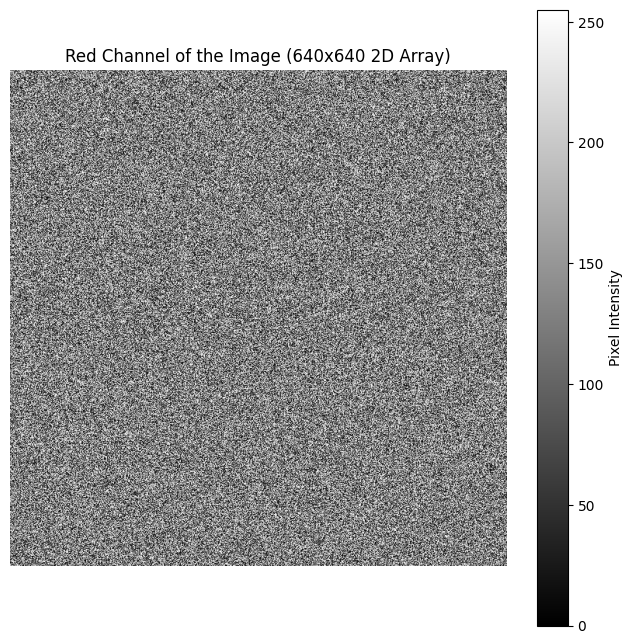

In [ ]:
# Plot the sliced 2D array
plt.figure(figsize=(8, 8))
plt.imshow(red_channel, cmap='gray') # 'gray' colormap is suitable for single channel data
plt.title('Red Channel of the Image (640x640 2D Array)')
plt.colorbar(label='Pixel Intensity')
plt.axis('off') # Hide axes for a cleaner image display
plt.show()


In [ ]:
import matplotlib.pyplot as plt


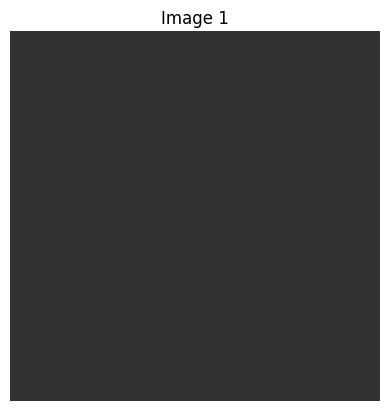

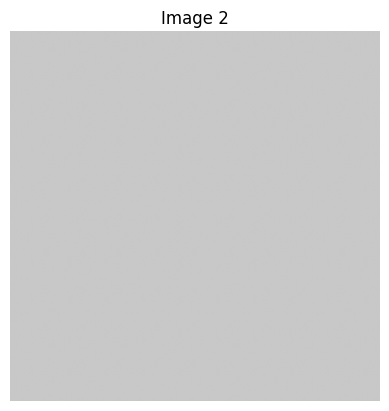

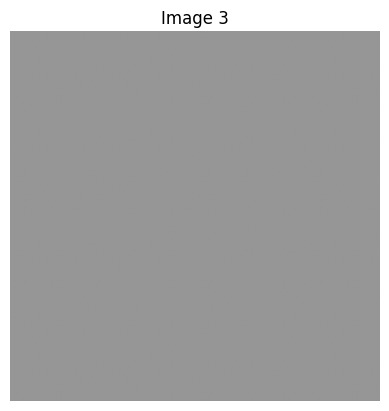

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

image1 = np.full((640, 640), 50)
image2 = np.full((640, 640), 200)
image3 = np.full((640, 640), 150)

plt.imshow(image1, cmap='gray', vmin=0, vmax=255)
plt.title("Image 1")
plt.axis('off')
plt.show()

plt.imshow(image2, cmap='gray', vmin=0, vmax=255)
plt.title("Image 2")
plt.axis('off')
plt.show()

plt.imshow(image3, cmap='gray', vmin=0, vmax=255)
plt.title("Image 3")
plt.axis('off')
plt.show()

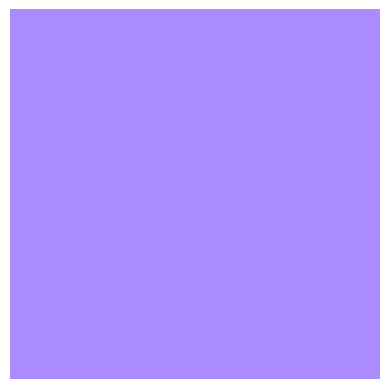

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random
arr = np.full((640,640),170)
arr1 = np.full((640,640),140)
arr2 = np.full((640,640),255)
arr3 = np.stack((arr,arr1,arr2),axis = -1)
plt.imshow(arr3, cmap='gray')
plt.axis('off')
plt.show()

Identical Pixels: 11420608
Percentage Match: 56.66279276533048


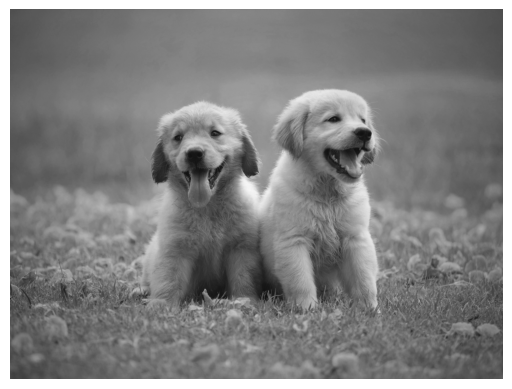

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("/content/pexels-chevanon-1108099.jpg")

if img is None:
    print("Image not found!")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Inbuilt grayscale
    gray_cv = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    height, width, channels = img.shape

    # Empty grayscale image
    gray = np.zeros((height, width), dtype=np.uint8)

    # Manual conversion
    for i in range(height):
        for j in range(width):
            R = img[i, j, 0]
            G = img[i, j, 1]
            B = img[i, j, 2]

            gray[i, j] = int(0.299 * R + 0.587 * G + 0.114 * B)

    # Compare
    error = gray.astype(np.int16) - gray_cv.astype(np.int16)

    same = np.sum(gray == gray_cv)
    total = gray.size

    print("Identical Pixels:", same)
    print("Percentage Match:", (same / total) * 100)

    plt.imshow(gray, cmap='gray')
    plt.axis('off')
    plt.show()